# Task 1: Titanic Survival Prediction
**MyDailyWork Data Science Internship**

Goal: Predict whether a passenger survived the Titanic. Every step below is one small cell.

## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Step 2: Read the dataset

In [2]:
# Read Dataset  (in Google Colab use: "/content/Titanic_Survival_Prediction.csv")
df = pd.read_csv("Titanic_Survival_Prediction.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,892,0,3,"Kelly, Mr. James",male,34.5,0,0,330911,7.8292,NaN,Q
1,893,1,3,"Wilkes, Mrs. James (Ellen Needs)",female,47.0,1,0,363272,7.0000,NaN,S
2,894,0,2,"Myles, Mr. Thomas Francis",male,62.0,0,0,240276,9.6875,NaN,Q
3,895,0,3,"Wirz, Mr. Albert",male,27.0,0,0,315154,8.6625,NaN,S
4,896,1,3,"Hirvonen, Mrs. Alexander (Helga E Lindqvist)",female,22.0,1,1,3101298,12.2875,NaN,S


In [3]:
# Rows and columns
df.shape

(418, 12)

In [4]:
# Missing values in each column
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age             86
SibSp            0
Parch            0
Ticket           0
Fare             1
Cabin          327
Embarked         0
dtype: int64

## Step 3: Explore the data (charts)

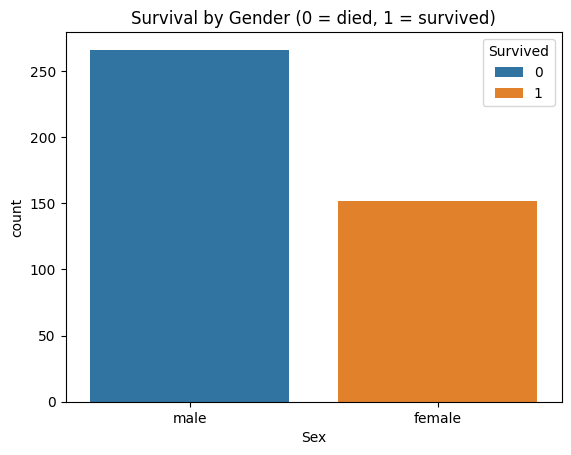

In [5]:
# How many men and women survived?
sns.countplot(x="Sex", hue="Survived", data=df)
plt.title("Survival by Gender (0 = died, 1 = survived)")
plt.show()

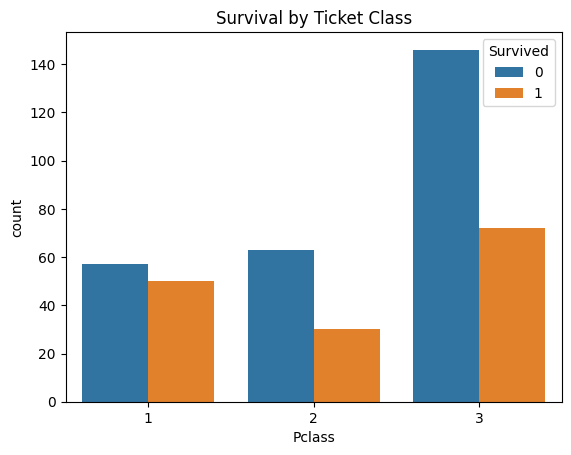

In [6]:
# Did ticket class matter?
sns.countplot(x="Pclass", hue="Survived", data=df)
plt.title("Survival by Ticket Class")
plt.show()

In [7]:
# THE TWIST: count survivors by gender
pd.crosstab(df["Sex"], df["Survived"])

Survived,0,1
Sex,,
female,0,152
male,266,0


**Look at the table above.** In this file every woman survived and every man died.
So gender alone predicts everything, and our models will score about 100%.
In the original bigger Titanic file the score is around 80%. Always question a perfect score!

## Step 4: Prepare the data

In [8]:
# Variables
features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
df = df[features + ["Survived"]].copy()

In [ ]:
# Fill missing values
df["Age"] = df["Age"].fillna(df["Age"].mean())            # mean for numeric col
df["Fare"] = df["Fare"].fillna(df["Fare"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])   # mode for categorical col

In [10]:
# Text to numbers
df["Sex"] = df["Sex"].map({"male": 0, "female": 1})
df["Embarked"] = df["Embarked"].map({"C": 0, "Q": 1, "S": 2})
df.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Survived
0,3,0,34.5,0,0,7.8292,1,0
1,3,1,47.0,1,0,7.0000,2,1
2,2,0,62.0,0,0,9.6875,1,0
3,3,0,27.0,0,0,8.6625,2,0
4,3,1,22.0,1,1,12.2875,2,1


In [11]:
# Assign X, Y values and split the data (70% train, 30% test)
x = df[features]       # input features
y = df["Survived"]     # output label
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, random_state=42)

## Step 5: Train three models and compare

In [12]:
models = {
    "Naive Bayes": GaussianNB(),
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
}

for name, model in models.items():
    model.fit(x_train, y_train)
    y_pred = model.predict(x_test)
    print(name, "accuracy:", accuracy_score(y_test, y_pred))

Naive Bayes accuracy: 1.0
Logistic Regression accuracy: 1.0
Random Forest accuracy: 1.0


## Step 6: Check the final model (Random Forest)

In [13]:
model = models["Random Forest"]
y_pred = model.predict(x_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00        85
           1       1.00      1.00      1.00        41

    accuracy                           1.00       126
   macro avg       1.00      1.00      1.00       126
weighted avg       1.00      1.00      1.00       126



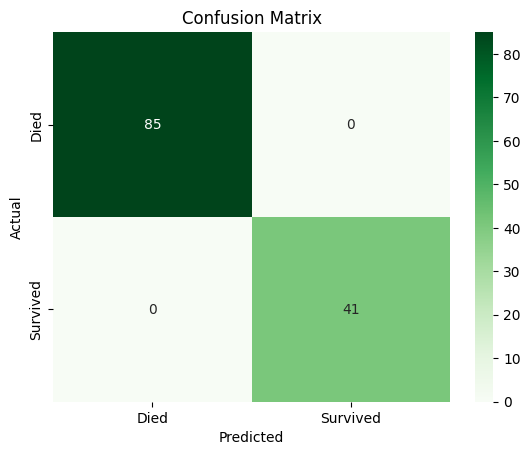

In [14]:
# Confusion matrix as a picture
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Greens",
            xticklabels=["Died", "Survived"], yticklabels=["Died", "Survived"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

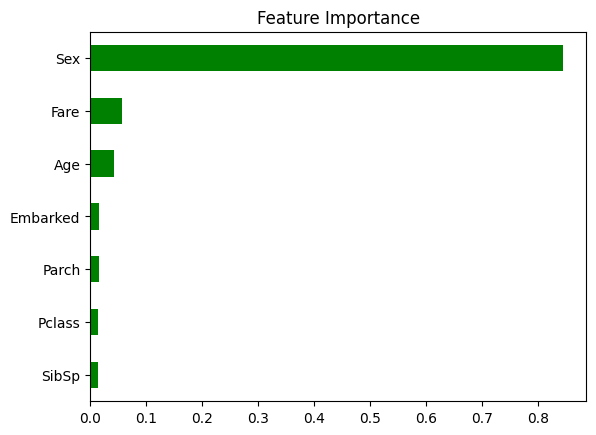

In [15]:
# Which feature matters most?
importance = pd.Series(model.feature_importances_, index=features).sort_values()
importance.plot(kind="barh", color="green")
plt.title("Feature Importance")
plt.show()

## Step 7: Predict for one new passenger

In [16]:
# Pclass, Sex (0 = male, 1 = female), Age, SibSp, Parch, Fare, Embarked (0 = C, 1 = Q, 2 = S)
passenger = pd.DataFrame([[1, 1, 28, 0, 0, 70, 2]], columns=features)

print("Prediction:", "Survived" if model.predict(passenger)[0] == 1 else "Did not survive")

Prediction: Survived


## Step 8: Save the model (the Streamlit app uses this file)

In [17]:
joblib.dump(model, "titanic_model.pkl")
print("Model saved!")

Model saved!
